# 03 · Baseline v1: CLIP on FairFace, with significance and retrieval utility

The final, clean baseline. Compared with notebook 02 it adds:

1. **Setup as a config choice:** FairFace crop (0.25 / 1.25) and gender balancing (Berg et al.'s protocol).
2. **Chance level and significance:** every number is compared with what a model with *no* preference
   would score (random rankings), and only effects beyond chance are highlighted.
3. **Age on adults only** (`age_adult`: 20-29 … 60+), so age no longer measures "children are not lawyers".
4. **Per-concept results** instead of category averages, which cancelled out opposite effects.
5. **Retrieval utility:** Recall@K on Flickr30K, the other half of the fairness-utility trade-off.

Every later mitigation notebook will follow this structure, so "before" and "after" line up.

**Colab:** Runtime → Change runtime type → **T4 GPU**.

## 0. Setup

Same as notebook 02. For a private repo, the `GITHUB_TOKEN` secret must be set (key icon, left sidebar).

In [9]:
import os, sys

REPO = "simalyucel/clip-bias-mitigation"
ROOT = "/content/clip-bias-mitigation"

try:
    from google.colab import userdata
    token = userdata.get("GITHUB_TOKEN")      # only needed for a private repo
except Exception:
    token = None
url = f"https://{token}@github.com/{REPO}.git" if token else f"https://github.com/{REPO}.git"

if not os.path.exists(ROOT):
    !git clone -q {url} {ROOT}
else:
    !git -C {ROOT} pull -q
%cd {ROOT}
!pip -q install open_clip_torch datasets
!pip -q install -e .
sys.path.insert(0, f"{ROOT}/src")

/content/clip-bias-mitigation
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for vlbias (pyproject.toml) ... done


In [ ]:
# must end with "36 passed"
!python -m pytest -q

....................................                                     [100%]
36 passed in 7.52s


In [10]:
import time
import numpy as np, pandas as pd, matplotlib.pyplot as plt, torch
from pathlib import Path

from vlbias.utils.config import load_yaml, set_seed
from vlbias.models.load import load_model
from vlbias.data.queries import load_queries
from vlbias.data.fairface import load_gallery
from vlbias.data.attributes import resolve_attributes
from vlbias.retrieval.embed import gallery_embeddings, encode_texts
from vlbias.retrieval.rank import top_k_indices
from vlbias.baseline import compute_nulls, chance_summary, evaluate, summarize, run_utility
from vlbias.analysis import concept_skew
from vlbias import plots

pd.set_option("display.precision", 3)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none - switch to a T4!")

GPU: Tesla T4


## 1. Choose the setup

Two configs, identical except for how the FairFace gallery is built:

| Config | Crop | Gallery | Why |
|---|---|---|---|
| `baseline_v1_berg.yaml` | 1.25 (face + hair, shoulders, background) | gender-balanced subsample | Berg et al. (2022)'s protocol; our pipeline reproduces their numbers within 0.02 |
| `baseline_v1.yaml` | 0.25 (tight face) | full validation split | standard Hugging Face version |

Pick one with `CONFIG` (run the notebook twice to compare). Embeddings are cached per setup, so
switching back is fast within a session. `USE_DRIVE = True` keeps the cache across sessions.

In [11]:
CONFIG = "configs/experiments/baseline_v1_berg.yaml"   # or "configs/experiments/baseline_v1.yaml"
USE_DRIVE = False

cfg = load_yaml(CONFIG)
CACHE_DIR = Path(cfg["cache_dir"])
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    CACHE_DIR = Path("/content/drive/MyDrive/thesis/embeddings")
set_seed(cfg["seed"])
cfg

{'seed': 0,
 'model': 'configs/models/clip_vitb32.yaml',
 'query_sets': ['configs/queries/chuang2023.yaml',
  'configs/queries/berg2022_test.yaml',
  'configs/queries/occupations.yaml'],
 'dataset': {'name': 'fairface',
  'split': 'validation',
  'padding': '1.25',
  'balance_gender': True,
  'balance_seed': 1,
  'max_images': None},
 'attributes': ['gender', 'race', 'age_adult'],
 'metrics': {'k': [100, 1000],
  'references': ['uniform', 'gallery'],
  'zero_floor': 0.5},
 'significance': {'n_null': 1000, 'seed': 0, 'alpha': 0.05},
 'utility': {'dataset': 'flickr30k', 'ks': [1, 5, 10]},
 'batch_size': 256,
 'cache_dir': 'data/embeddings',
 'output_dir': 'results/baseline_v1_berg'}

## 2. Model and queries

Unchanged from notebook 02: CLIP ViT-B/32 (OpenAI weights) and the 364 queries of the three query sets.

In [12]:
vlm = load_model(load_yaml(cfg["model"]))
queries = [q for path in cfg["query_sets"] for q in load_queries(path)]
qdf = pd.DataFrame([q.to_dict() for q in queries])
print(len(queries), "queries")
qdf.groupby(["query_set", "category"]).agg(concepts=("concept", "nunique"), templates=("template", "nunique"),
                                           queries=("text", "count"))

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


364 queries


concepts  templates  queries
query_set     category                                   
berg2022_test negative             15          8      120
              positive             16          8      128
              socioeconomic         2          8       16
chuang2023    negative              5          1        5
              positive              5          1        5
occupations   occupation           30          3       90

In [7]:
m = vlm.model  # the open_clip model
n = lambda mod: sum(p.numel() for p in mod.parameters())
img = n(m.visual)
txt = sum(p.numel() for name, p in m.named_parameters() if not name.startswith("visual"))
print(f"image {img/1e6:.1f}M | text {txt/1e6:.1f}M | embed dim {m.text_projection.shape[1]}")

image 87.8M | text 63.4M | embed dim 512


In [8]:
blocks = sum(p.numel() for p in m.transformer.parameters())
vocab = m.token_embedding.weight.numel()
print(f"transformer {blocks/1e6:.1f}M | token embedding {vocab/1e6:.1f}M")

transformer 37.8M | token embedding 25.3M


## 3. Gallery and attributes

`load_gallery` builds the gallery from the `dataset:` block (crop, balancing). `resolve_attributes` turns
the `attributes:` list into labels. For **`age_adult`**, faces under 20 get label −1 and are left out of
the age evaluation (the age results then come from searching the adult faces only). Gender and race are
still evaluated on all faces.

**Look at:** gender should be exactly 50/50 with the Berg config; the age plot shows how many faces
were excluded.

README.md:   0%|          | 0.00/5.89k [00:00<?, ?B/s]

1.25/train-00000-of-00004-e7151785539779(…): reconstructing file:   0%|          |  0.00B /  468MB            

1.25/train-00000-of-00004-e7151785539779(…): downloading bytes:           |  0.00B            

1.25/train-00001-of-00004-f38b58e3987f3f(…): reconstructing file:   0%|          |  0.00B /  466MB            

1.25/train-00001-of-00004-f38b58e3987f3f(…): downloading bytes:           |  0.00B            

1.25/train-00002-of-00004-239e931aa9c3b3(…): reconstructing file:   0%|          |  0.00B /  466MB            

... (4 outputs left out)

1.25/validation-00000-of-00001-09e3e67bb(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/86744 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10954 [00:00<?, ? examples/s]

fairface-1.25-validation-gbal1 10324 images


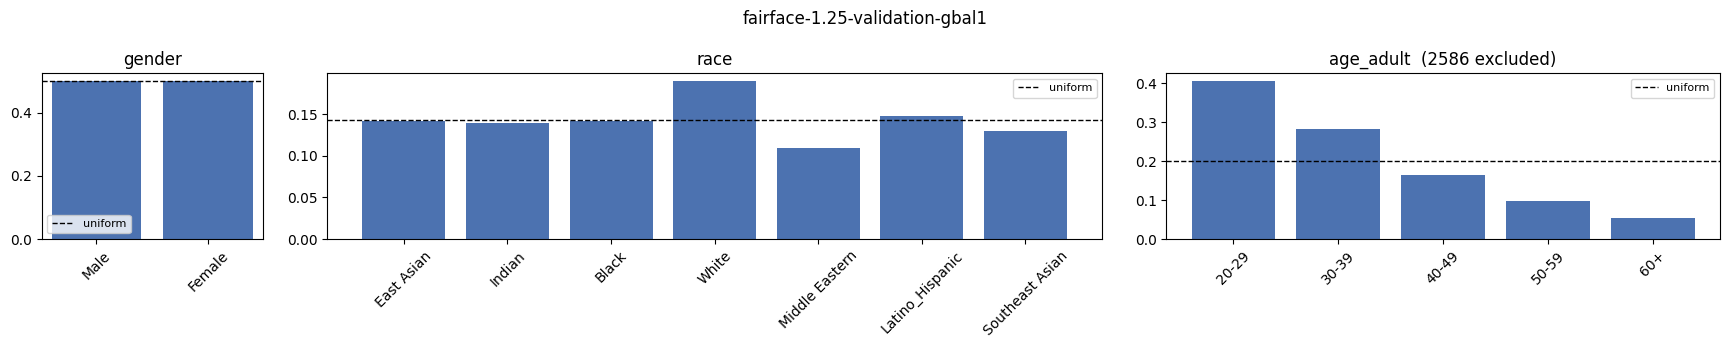

In [13]:
gallery = load_gallery(cfg["dataset"], cfg["seed"])
labels, names = resolve_attributes(gallery, cfg["attributes"])
print(gallery.name, len(gallery), "images")
plots.plot_composition(labels, names, title=gallery.name)

## 4. Embeddings

Encode every face once (cached) and the 364 queries.

In [16]:
g_emb = gallery_embeddings(vlm, gallery, CACHE_DIR, batch_size=cfg["batch_size"])
q_emb = encode_texts(vlm, [q.text for q in queries])
g_emb.shape, q_emb.shape

encoding images:   0%|          | 0/41 [00:00<?, ?it/s]

((10324, 512), (364, 512))

## 5. Chance level: what does a model with no preference score?

We draw `n_null` (1,000) **random rankings** of the gallery and compute every metric on them. This gives,
for each attribute × reference × k, the distribution of values that occur **by chance alone**.

Two uses:
- **Chance level** (`chance_mean`): the value a neutral model gets. Anything near it is not bias.
- **Significance:** an observed value is significant when random rankings almost never reach it
  (p-value). Because we test thousands of query × group cells, p-values are corrected with
  **Benjamini-Hochberg** (`p_adj`): among the effects we call significant, at most 5% are expected to
  be false alarms.

Under random ranking the result does not depend on the query, so this is computed once and reused.
It takes about a minute.

In [19]:
m, sig = cfg["metrics"], cfg["significance"]
t0 = time.time()
nulls = compute_nulls(labels, names, m["k"], m["references"], sig["n_null"], sig["seed"], m["zero_floor"])
chance = chance_summary(nulls)
print(f"{time.time() - t0:.0f}s")
chance.pivot_table(index=["attribute", "reference", "k"], columns="metric", values="chance_mean")

1s


metric                    max_skew  min_skew   ndkl
attribute reference k                              
age_adult gallery   100      0.276    -0.421  0.195
                    1000     0.094    -0.108  0.037
          uniform   100      0.706    -1.456  0.408
                    1000     0.704    -1.345  0.247
gender    gallery   100      0.073    -0.083  0.073
                    1000     0.024    -0.025  0.013
          uniform   100      0.073    -0.083  0.073
                    1000     0.024    -0.025  0.013
race      gallery   100      0.311    -0.440  0.294
                    1000     0.104    -0.115  0.057
          uniform   100      0.372    -0.515  0.306
                    1000     0.282    -0.282  0.069

### Result: chance level

**What the table shows.** The mean value of each metric over 1,000 random rankings of this gallery:
what a model with **no preference at all** would score. Any observed number has to be read against it.

**What it says.**
- **Chance is far from zero, especially at k = 100.** A random top-100 is a small sample, so its group
  mix fluctuates. For race (7 groups), a random ranking already reaches MaxSkew@100 = 0.31 on average,
  and its 95% range goes up to **0.53**. A single race query with MaxSkew@100 = 0.5 is therefore
  *not* evidence of bias.
- **Larger k = lower chance level** (race: 0.31 at k = 100, 0.10 at k = 1000): more images, less
  noise. Small effects can only be detected at k = 1000.
- **Gender:** gallery and uniform are identical, because the gallery is exactly 50/50.
- **Adult age, uniform reference:** chance is 0.70, because adults in FairFace are mostly 20–29. Against
  the gallery reference it drops to 0.09. Same lesson as section 5b of notebook 02, now for adults.

**Why it matters.** Most papers report raw MaxSkew with no reference point. Without the chance level,
a number like 0.3 cannot be interpreted: it is pure noise for race at k = 100, but a strong effect for
gender at k = 1000.

## 6. Run the evaluation

Same metrics as before, plus for every row:
- `per_query`: `max_skew_p`, `min_skew_p`, `ndkl_p`, their corrected `_p_adj`, and `_sig` flags;
- `per_group`: `chance_lo` / `chance_hi` (95% chance range of that group's Skew), `p_value`, `p_adj`,
  `significant`.

In [20]:
per_query, per_group = evaluate(q_emb, queries, g_emb, labels, names, ks=m["k"], references=m["references"],
                                zero_floor=m["zero_floor"], nulls=nulls, alpha=sig["alpha"])
for df in (per_query, per_group):
    df.insert(0, "model", vlm.name); df.insert(1, "dataset", gallery.name)
summary = summarize(per_query, chance)

out = Path(cfg["output_dir"]); out.mkdir(parents=True, exist_ok=True)
per_query.to_csv(out / "per_query.csv", index=False)
per_group.to_csv(out / "per_group.csv", index=False)
summary.to_csv(out / "summary.csv", index=False)
chance.to_csv(out / "chance.csv", index=False)
print(len(per_query), "per-query rows,", len(per_group), "per-group rows")

4368 per-query rows, 20384 per-group rows


## 7. Summary: observed vs chance

Gallery reference. For each metric: the mean over queries, the chance level, and the **share of queries
that are significantly biased** (after correction).

**Look at:** how far each mean is above its chance level, and the `share_…_sig` columns: "70% of
occupation queries are significantly gender-skewed" is a much stronger statement than a mean.

In [ ]:
cols = ["query_set", "attribute", "k",
        "max_skew_mean", "max_skew_chance", "share_max_skew_sig",
        "min_skew_mean", "min_skew_chance", "share_min_skew_sig",
        "ndkl_mean", "ndkl_chance", "share_ndkl_sig"]
summary.query("reference == 'gallery'")[cols].set_index(["query_set", "attribute", "k"])

max_skew_mean  max_skew_chance  \
query_set     attribute k                                      
berg2022_test age_adult 100           0.389            0.276   
                        1000          0.269            0.094   
              gender    100           0.257            0.073   
                        1000          0.166            0.024   
              race      100           0.765            0.311   
                        1000          0.493            0.104   
chuang2023    age_adult 100           0.502            0.276   
                        1000          0.330            0.094   
              gender    100           0.263            0.073   
                        1000          0.151            0.024   
              race      100           0.878            0.311   
                        1000          0.592            0.104   
occupations   age_adult 100           0.512            0.276   
                        1000          0.317            0.094   
              gender    100           0.432            0.073   
                        1000          0.338            0.024   
              race      100           0.615            0.311   
                        1000          0.372            0.104   

                             share_max_skew_sig  min_skew_mean  \
query_set     attribute k                                        
berg2022_test age_adult 100               0.038         -1.367   
                        1000              0.557         -0.879   
              gender    100               0.621         -0.427   
                        1000              0.807         -0.225   
              race      100               0.814         -1.540   
                        1000              0.992         -0.780   
chuang2023    age_adult 100                 0.1         -1.067   
                        1000                0.7         -0.644   
              gender    100                 0.6         -0.391   
                        1000                0.8         -0.197   
              race      100                 0.9         -2.251   
                        1000                1.0         -1.104   
occupations   age_adult 100               0.078         -0.823   
                        1000              0.589         -0.509   
              gender    100               0.867         -1.130   
                        1000              0.956         -0.636   
              race      100               0.633         -1.211   
                        1000              0.956         -0.702   

                              min_skew_chance share_min_skew_sig  ndkl_mean  \
query_set     attribute k                                                     
berg2022_test age_adult 100            -0.421              0.322      0.262   
                        1000           -0.108              0.788      0.102   
              gender    100            -0.083              0.621      0.146   
                        1000           -0.025              0.807      0.061   
              race      100            -0.440              0.761      0.538   
                        1000           -0.115              0.996      0.208   
chuang2023    age_adult 100            -0.421                0.3      0.280   
                        1000           -0.108                0.9      0.102   
              gender    100            -0.083                0.6      0.160   
                        1000           -0.025                0.8      0.058   
              race      100            -0.440                1.0      0.656   
                        1000           -0.115                1.0      0.284   
occupations   age_adult 100            -0.421              0.111      0.310   
                        1000           -0.108              0.678      0.104   
              gender    100            -0.083              0.867      0.282   
                        1000           -0.025              0.956      0.183   
      

### Result: observed bias vs chance, and how many queries are significantly biased

**What the table shows.** For each query set, attribute and k (gallery reference): the mean of each
metric, its chance level, and the **share of queries that are significantly biased** after
Benjamini-Hochberg correction (at most 5% of the flagged queries are expected to be false alarms).

**What it says (Berg et al.'s prompts, k = 1000).**

| Attribute | MaxSkew | Chance | × chance | Queries significantly biased |
|---|---|---|---|---|
| Race | 0.493 | 0.104 | ~4.7× | **99%** |
| Gender | 0.166 | 0.024 | ~7× | **81%** |
| Adult age | 0.269 | 0.094 | ~2.9× | **56%** |

- **Bias is the rule, not the exception:** almost every adjective query is significantly race-skewed,
  and 4 in 5 are gender-skewed, even though none of these words has anything to do with race or gender.
- **Occupations are the most gender-biased:** 87% (k = 100) and 96% (k = 1000) of occupation queries
  are significantly gender-skewed.
- **Chuang et al.'s 10 prompts:** 100% are significantly race-skewed (MinSkew) at both k.
- **k = 100 vs 1000:** bias is *larger* at k = 100, but *fewer* queries are significant there, because
  the chance level is higher (more noise). Example, adult age: only 4% significant on MaxSkew@100, but
  32% on MinSkew@100 and 56% on MaxSkew@1000. Both k values are needed: k = 100 for size, k = 1000
  for evidence.
- **Absent groups are mostly gone:** with adult age bands, 24.5% of age queries at k = 100 still miss one
  band entirely (usually 60+), and none do at k = 1000. With the 9 fine bins it was 96%.

**Why it matters.** "81% of neutral prompts significantly over-represent one gender" is a clearer and
more defensible claim than "mean MaxSkew = 0.166", and it is the kind of number a mitigation method
should bring down.

## 8. Uniform vs gallery reference

Kept for comparability with Berg et al. and Chuang et al., who use the uniform reference. With a
gender-balanced gallery, uniform = gallery for gender.

In [ ]:
summary.query("k == 1000").pivot_table(index=["query_set", "attribute"], columns="reference",
                                       values=["max_skew_mean", "max_skew_chance", "ndkl_mean"])

max_skew_chance         max_skew_mean          \
reference                       gallery uniform       gallery uniform   
query_set     attribute                                                 
berg2022_test age_adult           0.094   0.704         0.269   0.876   
              gender              0.024   0.024         0.166   0.166   
              race                0.104   0.282         0.493   0.579   
chuang2023    age_adult           0.094   0.704         0.330   0.809   
              gender              0.024   0.024         0.151   0.151   
              race                0.104   0.282         0.592   0.640   
occupations   age_adult           0.094   0.704         0.317   0.565   
              gender              0.024   0.024         0.338   0.338   
              race                0.104   0.282         0.372   0.452   

                        ndkl_mean          
reference                 gallery uniform  
query_set     attribute                    
berg2022_test age_adult     0.102   0.436  
              gender        0.061   0.061  
              race          0.208   0.228  
chuang2023    age_adult     0.102   0.364  
              gender        0.058   0.058  
              race          0.284   0.304  
occupations   age_adult     0.104   0.235  
              gender        0.183   0.183  
              race          0.141   0.154

### Result: uniform vs gallery reference (k = 1000)

**What the table shows.** Mean MaxSkew and NDKL against both references, with the chance level of each.

**What it says.**
- **Gender:** identical columns. The gallery is 50/50, so the two references coincide.
- **Race:** uniform is slightly higher (0.579 vs 0.493 for Berg prompts), with chance 0.282 vs 0.104:
  FairFace is not perfectly balanced across the 7 groups even after gender balancing.
- **Adult age:** uniform 0.876 vs gallery 0.269, with chance **0.704** vs 0.094. Almost all of the
  uniform number is the gallery's age distribution. What CLIP adds is the gap above chance: about 0.17
  against either reference.

**Why it matters.** For comparability with Berg et al. and Chuang et al., the uniform column is the one
to quote. For the conclusions of the thesis, the gallery column minus chance is the honest measure of
what the model adds.

## 9. Per-concept results (adjectives)

One row per concept (mean over its 8 templates), one column per group, gallery reference, k = 100.
**Only cells that differ from chance are coloured** (bold numbers); grey numbers are within chance.
The chance range of a mean over 8 templates is narrower than that of a single query, so consistent small
effects can still be significant.

**Look at:** for gender, which words pull towards which gender; for race, rows where one group is
strongly red and another strongly blue; for age, whether any adult age band is systematically favoured.

gender: 60 of 66 concept x group cells differ from chance


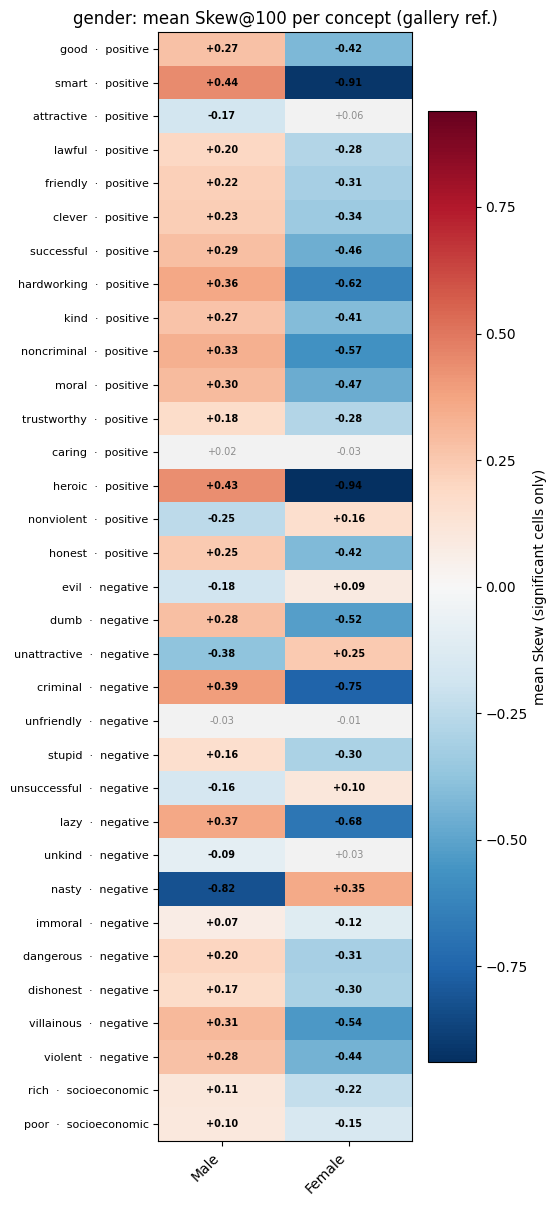

race: 181 of 231 concept x group cells differ from chance


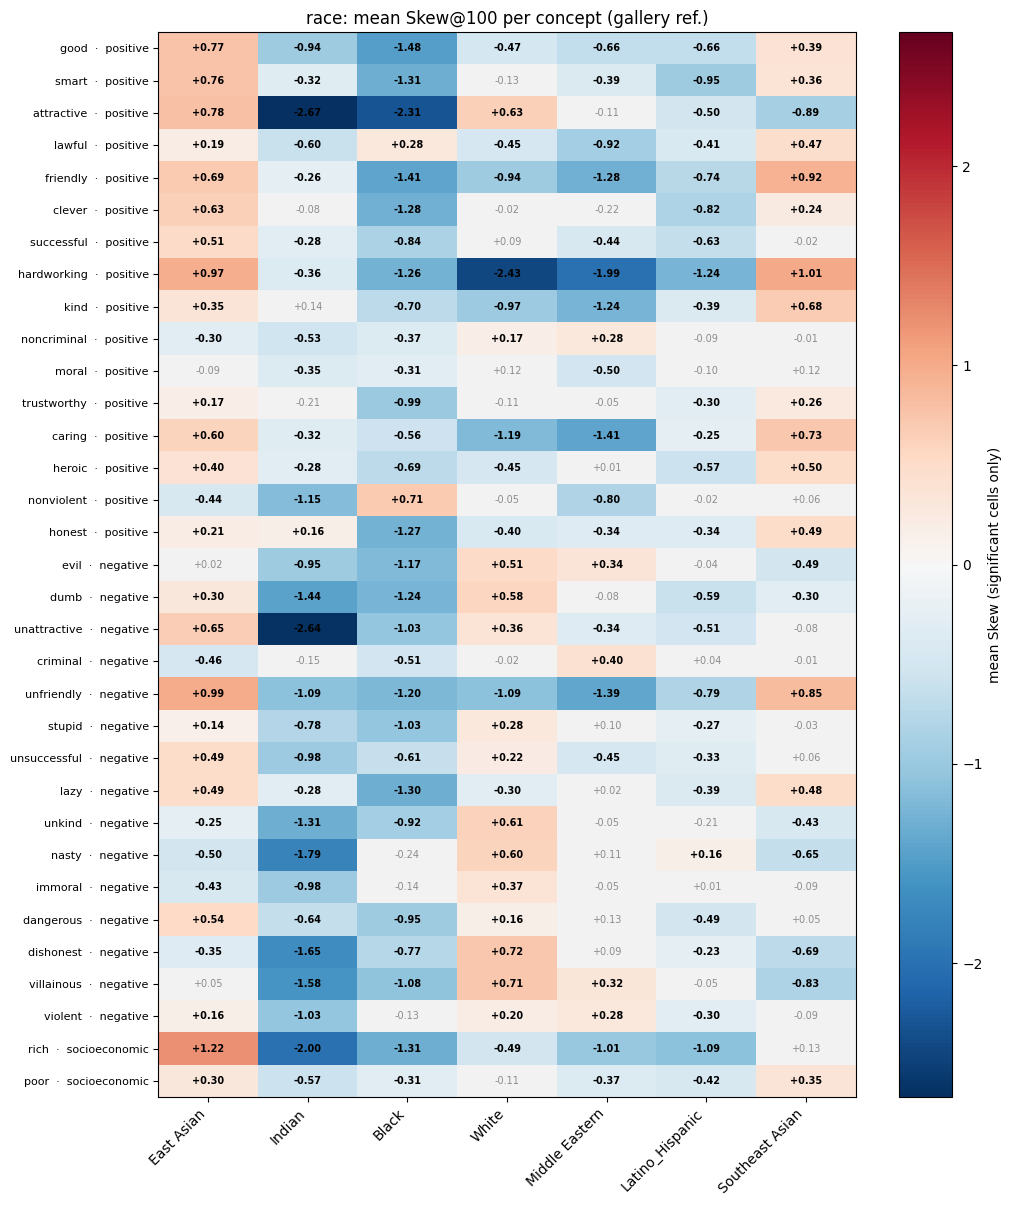

age_adult: 122 of 165 concept x group cells differ from chance


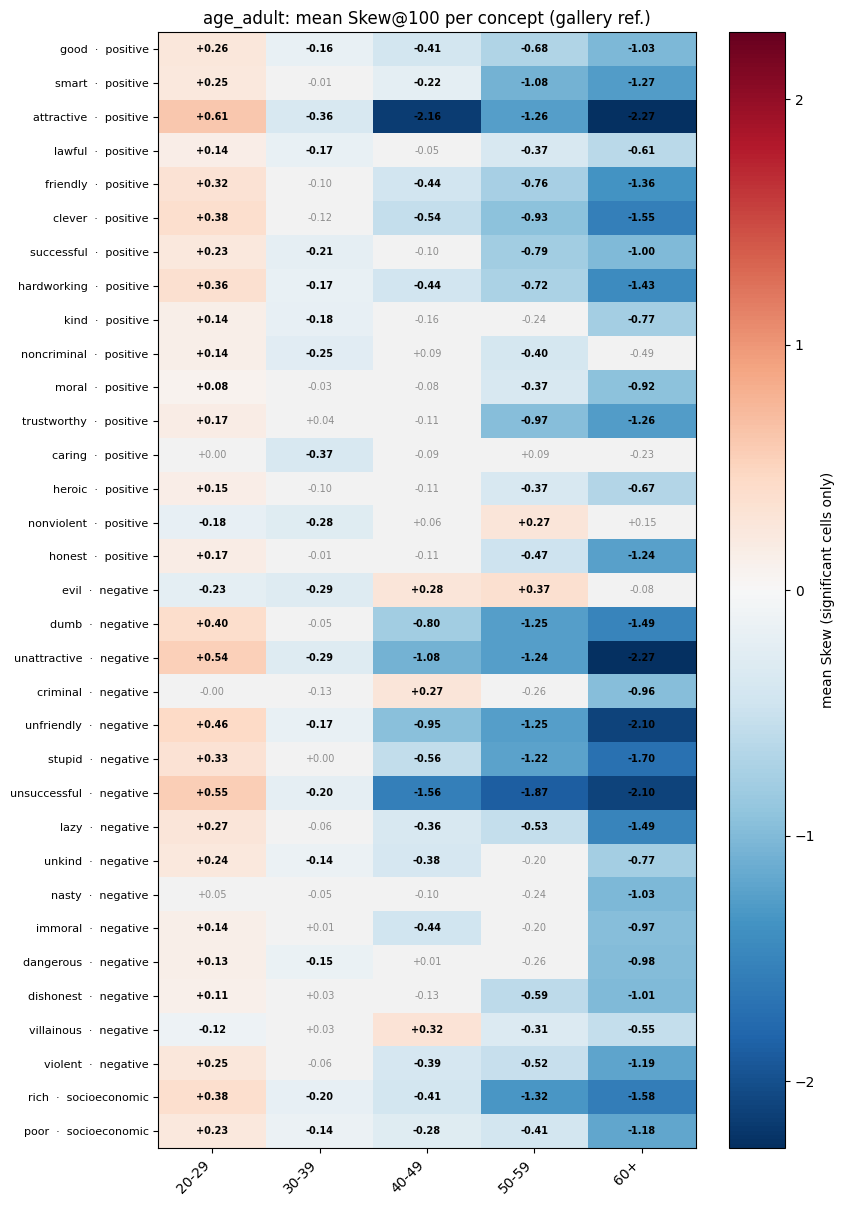

In [ ]:
concept_tables = {}
for attr in cfg["attributes"]:
    cs = concept_skew(per_group, nulls, attr, "gallery", 100, query_set="berg2022_test", alpha=sig["alpha"])
    concept_tables[attr] = cs
    print(f"{attr}: {cs['significant'].sum()} of {len(cs)} concept x group cells differ from chance")
    plots.plot_concept_heatmap(cs, names[attr], f"{attr}: mean Skew@100 per concept (gallery ref.)")

### Result: gender, per concept (adjectives)

**What the plot shows.** Mean Skew@100 per concept (over its 8 templates) for each gender, gallery
reference. Coloured, bold cells differ significantly from chance; grey cells do not.

**What it says.**
- **25 of 33 concepts favour men, positive and negative alike.** The strongest are heroic (women −0.94),
  smart (−0.91), criminal (−0.75), lazy (−0.68) and hardworking (−0.62). A Skew of −0.9 means women get
  only ~40% of their expected share.
- **Only a handful favour women:** nasty (+0.35), unattractive (+0.25), nonviolent (+0.16),
  unsuccessful (+0.10) and evil (+0.09). These are mostly **appearance** and **social-negative** words.
- **Within chance:** caring, unfriendly, and for women also attractive and unkind.
- This looks like a **"male-as-default person"** effect: when the prompt says "person", CLIP leans male
  regardless of the word, except for appearance-related words. Competence and courage words (smart,
  heroic, hardworking) show the strongest male skew, which matches a familiar stereotype.
- **Compared with the 0.25-crop run** (notebook 02), the male lean is much more uniform. The wider crop
  shows hair and clothing, which give CLIP stronger gender cues.

**Why it matters.** Gender bias here is not a few stereotyped words but a general default, which a
mitigation method has to address across the board, not word by word.

### Result: race, per concept (adjectives)

**What the plot shows.** Mean Skew@100 per concept and race group, gallery reference; coloured cells
differ from chance.

**What it says.**
- **A general visibility gap:** averaged over all 33 concepts, **Black (−0.84) and Indian (−0.85)** faces
  are under-retrieved and **East Asian (+0.29)** and Southeast Asian (+0.11) faces over-retrieved,
  whatever the word means. Black and Indian are under-represented under **all 8 templates**, so this is
  the most robust finding.
- **Word-specific stereotypes on top of it:**
  - *attractive*: Indian **−2.67**, Black **−2.31**; East Asian +0.78, White +0.63 (a beauty-standard bias);
  - *rich*: East Asian **+1.22**; Indian −2.00, Black −1.31, Latino_Hispanic −1.09, Middle Eastern −1.01;
  - *criminal*: Middle Eastern **+0.40** is the only significant over-representation.
- **Careful with the White column:** White looks over-represented for several negative words (dishonest
  +0.72, villainous +0.71, unkind +0.61) and strongly under-represented for some positive ones
  (hardworking −2.43). But this pattern **depends on the template**. With "A {} person", White faces are
  under-retrieved for *every* word (−1.26 on average), and the top 100 contains **zero White faces** for
  "A friendly person", "A kind person", "A good person", "A hardworking person" and also
  "A unfriendly person". Opposite words giving the same result shows the template, not the meaning, is
  driving it.

**Why it matters.** Race bias combines a robust exclusion of Black and Indian faces with weaker,
template-dependent effects. The thesis should claim the first firmly and present the second with the
template caveat.

### Result: adult age, per concept (adjectives)

**What the plot shows.** Mean Skew@100 per concept and adult age band (20–29 … 60+), gallery reference.
Faces under 20 are excluded from this attribute.

**What it says.**
- **"Person" means young:** 20–29 is over-represented for **29 of 33** concepts and 60+ under-represented
  for **32 of 33**, again regardless of whether the word is positive or negative.
- **The strongest gaps:** attractive (60+ −2.27, 40–49 −2.16), unattractive (60+ −2.27),
  unsuccessful and unfriendly (60+ −2.10), and stupid (60+ −1.70).
- **The few exceptions are "villain" words:** evil, villainous and criminal over-represent 40–49
  (+0.27 to +0.32).
- 60+ is a small share of the gallery, so a few of its most negative values come from queries where it
  is absent from the top 100 (24.5% of age queries at k = 100).

**Why it matters.** Excluding children made age meaningful: the result is a clear **youth default**,
with older adults disappearing from results for almost any description. That was invisible with the 9
fine bins, where children dominated the numbers.

In [21]:
r = per_group.query("query_set == 'berg2022_test' and attribute == 'race' "
                    "and reference == 'gallery' and k == 100").copy()

# 1) Does the phrasing problem happen for other groups too?
#    Mean Skew per group under each phrasing:
display(r.pivot_table(index="template", columns="group", values="skew").round(2))

# 2) Word-level effect = Skew minus the group's usual level (under the same phrasing)
r["word_effect"] = r["skew"] - r.groupby(["template", "group"])["skew"].transform("mean")
w = r.groupby(["concept", "group"])["word_effect"].agg(["mean", "std"]).round(2)
display(w.query("group == 'Indian'").sort_values("mean"))

group,Black,East Asian,Indian,Latino_Hispanic,Middle Eastern,Southeast Asian,White
template,,,,,,,
A cropped photo of a {} face,-1.22,0.72,-1.19,-0.26,-0.30,0.20,0.06
A photo of a {} person,-1.30,0.26,-0.85,-0.38,-0.35,0.26,-0.02
A {} individual,-0.57,0.41,-0.25,-0.46,-0.59,0.45,-0.64
A {} person,-0.67,0.29,-0.42,-0.48,-0.96,0.66,-1.26
This individual is {},-0.20,0.08,-0.76,-0.25,0.03,-0.09,0.05
This is a photo of a {} person,-0.97,-0.12,-1.20,-0.51,-0.35,-0.37,0.41
This is the face of a {} person,-1.19,0.29,-1.12,-0.48,-0.12,-0.30,0.55
This person is {},-0.59,0.37,-0.97,-0.46,-0.28,0.04,0.06


,,mean,std
concept,group,,
attractive,Indian,-1.83,0.68
unattractive,Indian,-1.79,0.73
rich,Indian,-1.15,1.40
nasty,Indian,-0.95,0.67
dishonest,Indian,-0.81,1.08
villainous,Indian,-0.74,0.69
dumb,Indian,-0.59,0.68
unkind,Indian,-0.47,0.47
nonviolent,Indian,-0.31,0.69


### Check: template effects and word-level effects (race)

**Why.** In the race heatmap (section 9), opposite words sometimes gave the same result: Indian faces
were under-represented for both *attractive* and *unattractive*, and White faces disappeared for both
*friendly* and *unfriendly* with the template "A {} person". If CLIP reacted to the meaning of the word,
opposite words should give opposite results. Two checks separate the effect of the **template**, the
**group** and the **word**.

**Check 1: mean Skew@100 per group under each template** (Berg et al. adjectives, gallery reference).

- **Stable under every template:** Black (−0.20 to −1.30), Indian (−0.25 to −1.20) and Latino_Hispanic
  (−0.25 to −0.51) are under-represented under all 8 templates. East Asian is over-represented under
  7 of 8, Middle Eastern under-represented under 7 of 8.
- **Template-dependent:** White goes from −1.26 ("A {} person") to +0.55 ("This is the face of a {} person"),
  Southeast Asian from +0.66 to −0.37. The short templates ("A {} person", "A {} individual") push White
  and Middle Eastern down and Southeast Asian up, so the template effect is not specific to White.

**Check 2: word effect for Indian faces** = Skew minus the group's mean Skew under the same template,
averaged over templates. A word effect is reliable only if its mean is clearly larger than its std
(i.e. it is consistent across templates).

- **Opposite words move together:** attractive −1.83 (std 0.68) and unattractive −1.79 (std 0.73);
  criminal +0.70 and noncriminal +0.32; lazy +0.57 and hardworking +0.49.
- **Not reliable:** rich −1.15 with std 1.40.

**What it says.**
- The **general under-representation of Black, Indian and Latino_Hispanic faces** is robust: it holds
  under every template.
- Results for **White and Southeast Asian** depend on the template and are **not interpreted** at the
  word level.
- Word-level effects follow the **topic** of the word (appearance, crime, work) rather than its
  **polarity**: appearance-related words exclude Indian faces beyond their usual level, whether
  positive or negative. This is consistent with CLIP's known difficulty with negation.

**Why it matters.** Grouping words into "positive" and "negative" can hide topic effects, and a single
template can change the direction of a result. Word-level stereotypes are therefore claimed only when
they are consistent across templates and not explained by the topic alone. This check will be repeated
after each mitigation method.

## 10. Occupations

**Gender:** Skew of *Female* per occupation (mean over 3 templates). The grey band is the 95% chance
range: bars outside it are coloured, bars inside it are grey.

**Race:** the full occupation × group heatmap, same convention as section 9.

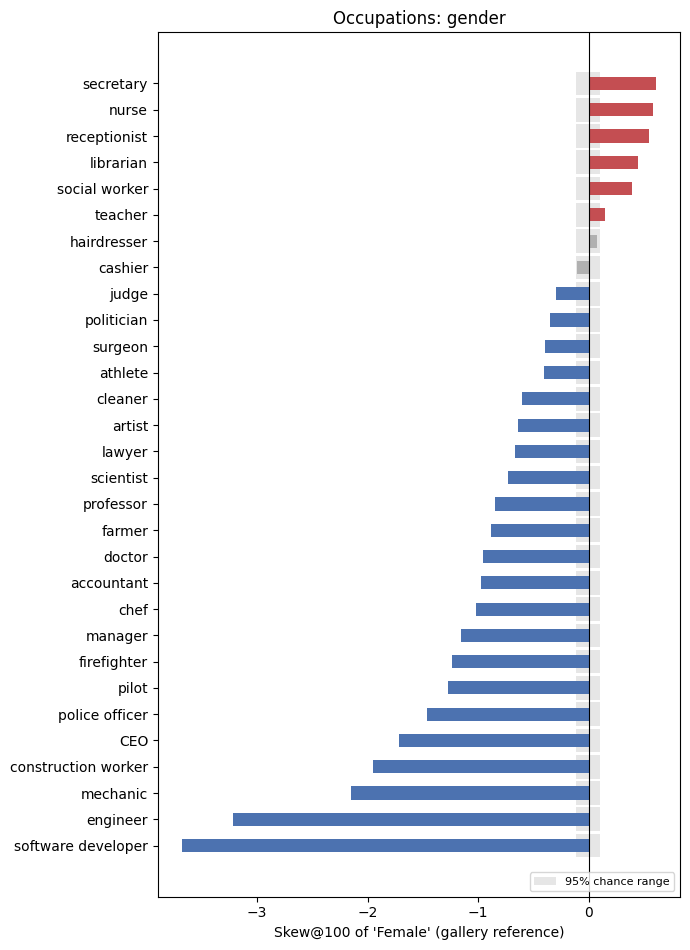

In [ ]:
occ = {attr: concept_skew(per_group, nulls, attr, "gallery", 100, query_set="occupations", alpha=sig["alpha"])
       for attr in cfg["attributes"]}
plots.plot_concept_bars(occ["gender"], "Female", "Occupations: gender",
                        "Skew@100 of 'Female' (gallery reference)")

### Result: occupations and gender

**What the plot shows.** Skew@100 of *Female* per occupation (mean over 3 templates). Grey band = 95%
chance range; coloured bars are significant, grey bars are within chance.

**What it says.**
- **22 of 30 occupations significantly favour men; 6 favour women** (secretary, nurse, receptionist,
  librarian, social worker, teacher). Hairdresser and cashier are within chance.
- **The ceiling again:** with a 50/50 gallery, the maximum possible Female Skew is ln(2) ≈ 0.69.
  Secretary, nurse and receptionist are close to it (~90% women or more).
- **Women vanish from technical jobs.** "A photo of an engineer" and "a photo of a software developer"
  return **0 women in the top 100**. The other software developer templates return 1 and 4.
- **Compared with real-world statistics:**
  - Doctor sits at about −0.95, i.e. ~19% women in the top 100, while women are about half of doctors
    in OECD countries: strong **amplification**.
  - CEO, at about −1.72 (9% women), is within the real-world range (~7% in the largest companies, ~24%
    in mid-size ones).

**Why it matters.** Occupations are the field's standard benchmark and the clearest case of
stereotyping. The comparison with real statistics shows CLIP sometimes mirrors and sometimes amplifies
reality, so the choice of reference distribution (custom vs gallery) changes the conclusion per job.

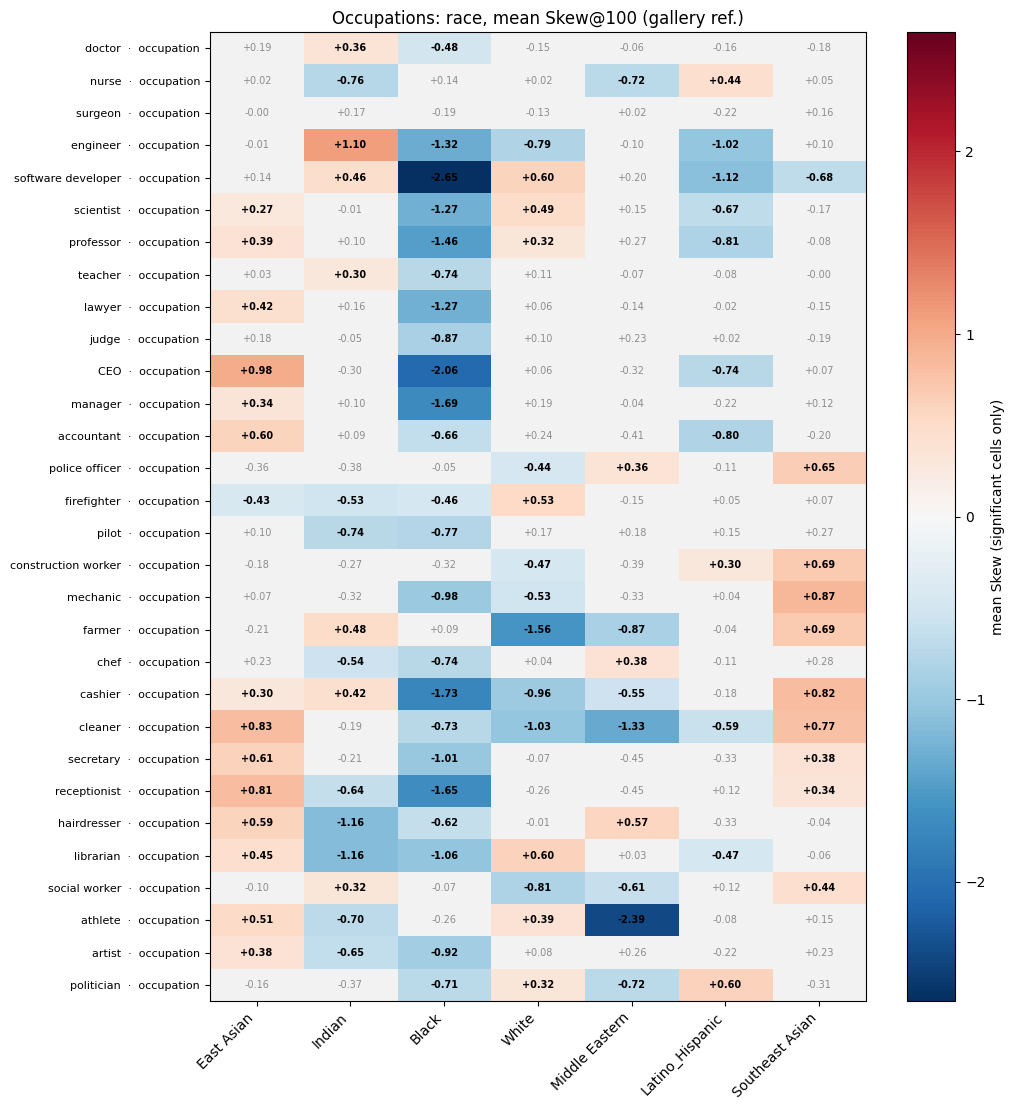

In [ ]:
plots.plot_concept_heatmap(occ["race"], names["race"], "Occupations: race, mean Skew@100 (gallery ref.)")

### Result: occupations and race

**What the plot shows.** Mean Skew@100 per occupation and race group; coloured cells differ from chance.

**What it says.**
- **Black faces are under-retrieved for almost every occupation (−0.88 on average) and significantly
  over-retrieved for none.** The largest gaps are software developer (−2.65), CEO (−2.06), cashier
  (−1.73), manager (−1.69), receptionist (−1.65) and professor (−1.46).
- **Recognisable stereotypes:**
  - **Indian → engineer (+1.10)** and software developer (+0.46);
  - **East Asian → CEO (+0.98)**, receptionist (+0.81), cleaner (+0.83);
  - **Southeast Asian → manual and service jobs**: mechanic (+0.87), cashier (+0.82), cleaner (+0.77),
    farmer and construction worker (+0.69);
  - **White** → firefighter (+0.53), software developer and librarian (+0.60), but farmer **−1.56**;
  - **Middle Eastern → athlete −2.39**; **Latino_Hispanic** → politician (+0.60).
- **Different from the 0.25-crop run:** athlete no longer over-represents Black faces. The wider crop adds
  clothing and background, which changes which visual cues CLIP matches.

**Why it matters.** For occupations, race bias is mostly **exclusion of Black faces** plus specific
occupational stereotypes per group, and it is sensitive to how much context the image shows.

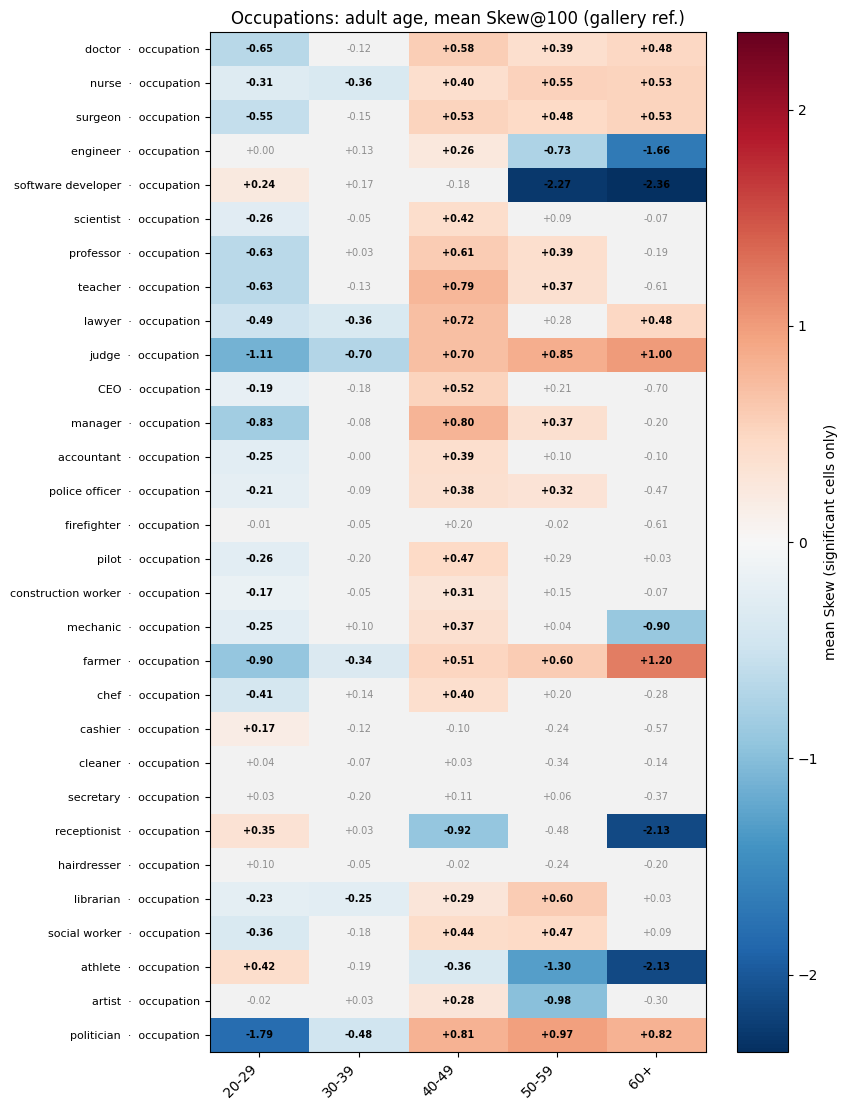

In [ ]:
plots.plot_concept_heatmap(occ["age_adult"], names["age_adult"], "Occupations: adult age, mean Skew@100 (gallery ref.)")

### Result: occupations and adult age

**What the plot shows.** Mean Skew@100 per occupation and adult age band; coloured cells differ from
chance.

**What it says.**
- **A seniority pattern:** status and expertise jobs over-represent 40+ and under-represent 20–29:
  judge (20–29 −1.11, 60+ +1.00), politician (20–29 −1.79, 50–59 +0.97), doctor, lawyer, manager and
  professor. Farmer is strongly older (60+ **+1.20**).
- **Tech and physical jobs are young:** software developer (50–59 −2.27, 60+ −2.36), engineer (60+
  −1.66), athlete (50–59 −1.30, 60+ −2.13). Receptionist also excludes 60+ (−2.13).
- **Part of this is realistic.** Judges really are older on average than athletes. For age × occupation,
  the gallery reference ("every job should show the same age mix") is a questionable target. A custom
  reference with real age statistics per occupation would be the fairer test.

**Why it matters.** Not every skew is unfair: this is the clearest case in the baseline where the choice
of reference distribution is a normative decision that the thesis has to state explicitly.

## 11. How much does the wording matter?

Same plot as notebook 02, now on the chosen setup.

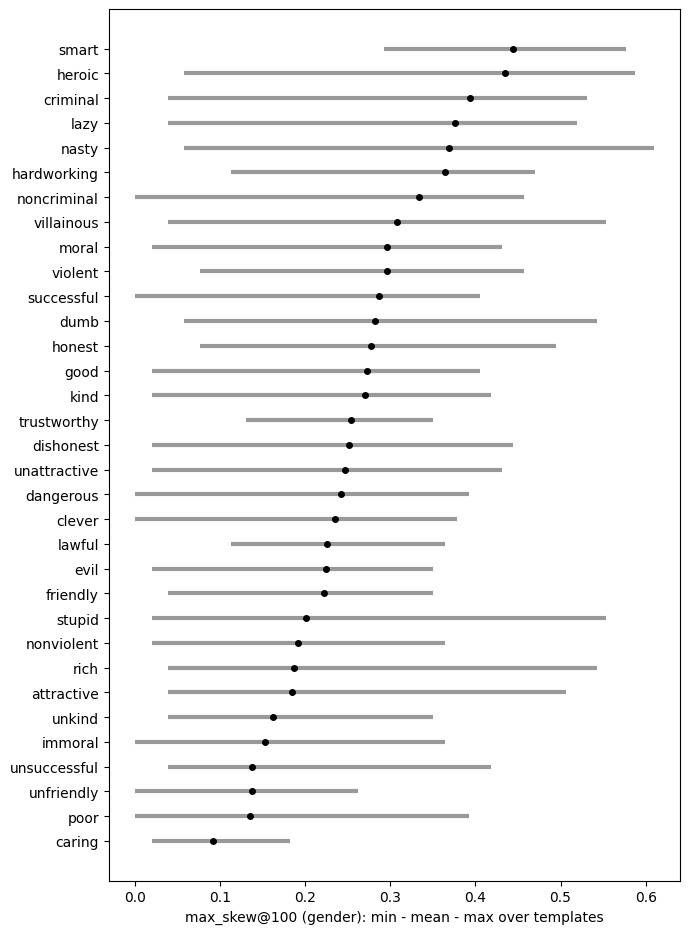

mean std across templates: 0.138 | std between concept means: 0.088


In [ ]:
spread = plots.plot_template_spread(per_query, "gender", "berg2022_test")
print("mean std across templates:", round(spread["std"].mean(), 3),
      "| std between concept means:", round(spread["mean"].std(), 3))

### Result: how much does the wording matter?

**What the plot shows.** For each of Berg et al.'s 33 concepts: mean gender MaxSkew@100 (dot) and its
range across the 8 templates (line), gallery reference.

**What it says.**
- **Wording matters more than meaning.** The spread across templates of the same concept (mean std
  **0.138**) is clearly **larger than the spread between concepts** (std 0.088). With the wide crop this
  effect is stronger than in the 0.25-crop run (0.13 vs 0.10).
- **Templates differ systematically** (mean gender MaxSkew@100): "A {} individual" **0.356** vs
  "This person is {}" **0.152**, a factor of 2.3 from the sentence frame alone.
- The same holds for race (see the race heatmap): one template ("A {} person") removes White faces
  for every word.

**Why it matters.** Any result from a single template is fragile, which weakens comparisons based on
Chuang et al.'s one-template prompts. In the thesis, results are always averaged over templates, the
spread is reported, and mitigation methods will be tested on templates they were not tuned on.

## 12. Retrieval utility: Flickr30K Recall@K

Fairness alone is not enough: a "debiased" model that retrieves the wrong images is useless. Utility is
measured on the standard **Flickr30K 1k test split** (1,000 images, 5 captions each):

- **text → image Recall@K:** for each caption, is its image among the K most similar images?
- **image → text Recall@K:** for each image, is one of its captions among the K most similar captions?

Higher is better. **Sanity check:** Berg et al. (2022) report text → image Recall@5 = **83.6** for CLIP
ViT-B/32. The first run downloads the dataset (small mirror first; if it is unavailable the full 4.4 GB
set is downloaded and filtered, which takes longer).

In [ ]:
utility = run_utility(vlm, cfg["utility"], CACHE_DIR)
utility.insert(0, "model", vlm.name)
utility.to_csv(out / "utility.csv", index=False)
display(utility.pivot(index="k", columns="direction", values="recall").round(1))
r5 = utility.query("direction == 'text_to_image' and k == 5")["recall"].iloc[0]
print(f"text->image R@5: ours {r5:.1f} vs Berg et al. 83.6")

README.md:   0%|          | 0.00/754 [00:00<?, ?B/s]

flickr_1k_test_image_text_retrieval.py:   0%|          | 0.00/2.79k [00:00<?, ?B/s]

TEST/test/0000.parquet: reconstructing file:   0%|          |  0.00B /  142MB            

TEST/test/0000.parquet: downloading bytes:           |  0.00B            

Generating test split: 0 examples [00:00, ? examples/s]

Filter:   0%|          | 0/1000 [00:00<?, ? examples/s]

encoding images:   0%|          | 0/4 [00:00<?, ?it/s]

direction,image_to_text,text_to_image
k,,
1,76.9,58.0
5,94.2,83.0
10,97.8,89.0


text->image R@5: ours 83.0 vs Berg et al. 83.6


### Result: retrieval utility on Flickr30K

**What the table shows.** Recall@K (%) on the Flickr30K 1k test split, 1,000 images × 5 captions.

| K | text → image | image → text |
|---|---|---|
| 1 | 58.0 | 76.9 |
| 5 | **83.0** | 94.2 |
| 10 | 89.0 | 97.8 |

**What it says.**
- **Utility pipeline validated:** text → image Recall@5 = 83.0 vs **83.6** reported by Berg et al. for
  the same model, a difference of 0.6 points.
- Image → text is higher because each image has 5 correct captions, and finding any one of them counts
  as a hit.
- In words: for 58% of captions the correct image is the very first result, and for 89% it is in the
  top 10.

**Why it matters.** These are the "before" values of the fairness-utility trade-off. Every mitigation
method will be judged on how much it lowers the bias numbers above *and* how much of this Recall it
keeps. Berg et al. found some debiasing methods lose 20+ points here.

## 13. Look at the images

Top results for any query, with labels.

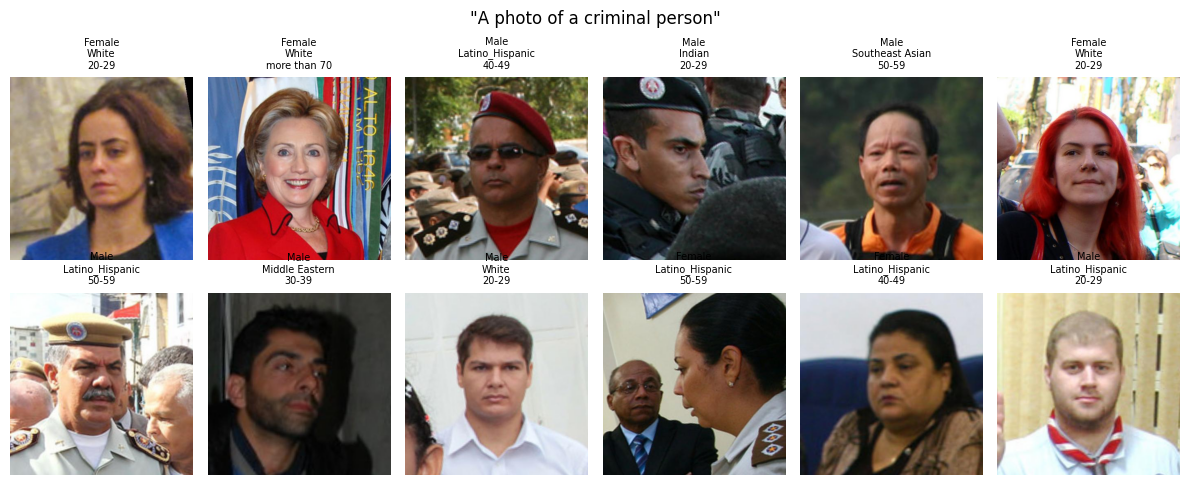

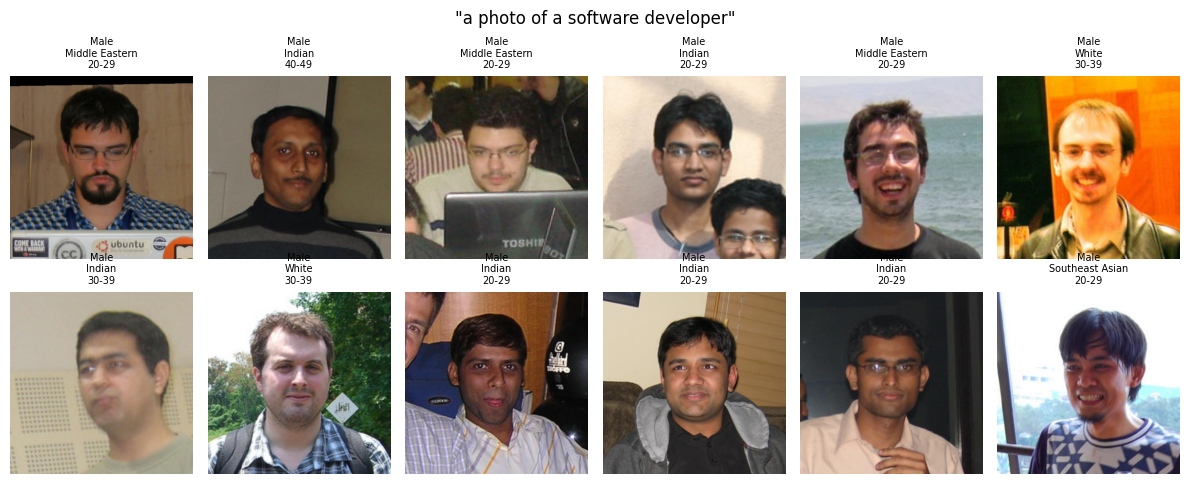

In [ ]:
def show(query, k=12):
    e = encode_texts(vlm, [query])
    top = top_k_indices(e, g_emb, k)[0]
    fig, axes = plt.subplots(2, k // 2, figsize=(2 * k // 2, 5))
    for ax, i in zip(axes.flat, top):
        ax.imshow(gallery.images[int(i)]["image"]); ax.axis("off")
        ax.set_title("\n".join(gallery.label_names[a][gallery.labels[a][i]] for a in ("gender", "race", "age")),
                     fontsize=7)
    fig.suptitle(f'"{query}"'); plt.tight_layout(); plt.show()

show("A photo of a criminal person")
show("a photo of a software developer")

### Result: what "A photo of a criminal person" retrieves (wide crop)

**What it shows.** The 12 most similar faces with their labels.

**What it says.**
- **Context, not faces:** with the 1.25 crop, several of the top results show **police or military
  uniforms** (berets, epaulettes, a crowd of officers). CLIP is matching *crime-related context*, not
  anything about the person's face. With the tight 0.25 crop (notebook 02), the top results were
  instead blurry, unsmiling close-ups: **the crop changes what drives the retrieval.**
- 12 images are too few to conclude anything. Averaged over all 9 "criminal" prompts at k = 100:
  - gender: men **+0.39**, women −0.75;
  - race: Middle Eastern **+0.40**; Black −0.67, East Asian −0.50;
  - age: 40–49 +0.30, 60+ −0.82.

**Why it matters.** It shows a limitation of face benchmarks: background and clothing are confounders
that FairFace labels do not capture. That is worth stating in the report, and it is a reason to compare
both crops when testing mitigation.

### Result: what "a photo of a software developer" retrieves

**What it shows.** The 12 most similar faces with their labels.

**What it says.**
- **12 of 12 are men**, 11 aged 20–39; 6 Indian, 3 Middle Eastern, 2 White, 1 Southeast Asian, no Black,
  no East Asian.
- **Visible context cues:** laptops (one with stickers, one with a brand logo), glasses and casual
  clothing. CLIP matches the *scene* of programming as much as the person.
- This matches the metrics exactly: **0 women in the top 100** for this prompt, Indian (+0.46) and White
  (+0.60) over-represented, Black at −2.65, and 50+ almost absent.

**Why it matters.** It is the clearest single example of the baseline's stereotypes. Gender, race and
age bias all show up in one query, which makes it a good figure for the report and a good test case
for mitigation.

## 14. Save

All outputs plus the exact config used. Download the zip and keep it **outside** the repo, in a folder
named after the setup and date.

In [ ]:
import yaml
with open(out / "config_used.yaml", "w") as f:
    yaml.safe_dump(cfg, f, sort_keys=False)
!cd {out} && zip -q -r /content/{out.name}_results.zip .
from google.colab import files
files.download(f"/content/{out.name}_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## The result files

| File | Rows | Contents |
|---|---|---|
| `per_query.csv` | 4,368 | each query × attribute × reference × k: metrics + p-values (`_p`, `_p_adj`) + flags (`_sig`) |
| `per_group.csv` | 20,384 | the same × each group: Skew, 95% chance range, p-value, `significant` |
| `summary.csv` | 36 | means over queries + chance level + share of significant queries: **the report tables** |
| `chance.csv` | 36 | chance mean and 95% range of every metric (random rankings) |
| `utility.csv` | 6 | Flickr30K Recall@1/5/10, both directions |
| `config_used.yaml` | – | exact settings of this run (setup B: 1.25 crop, gender-balanced, adult age, n_null 1000) |

**What the files show that the plots don't.**
- **Share of significant query × group cells** (gallery reference, k = 100 / 1000):
  gender **68% / 84%**, race 36% / 66%, adult age 26% / 61%.
- **The most extreme single queries:**
  - Gender: "a photo of an engineer" and "a photo of a software developer" (0 women in the top 100).
  - Race: "A friendly / kind / good / caring / hardworking / unfriendly person" (0 White faces, Southeast
    Asian at ~3–4× its share). This is the template effect described in section 9.
- **p-value resolution:** with 1,000 random rankings the smallest possible p-value is about 0.001.
  Many strongly biased queries sit at that floor, so p-values rank effects only up to that point; the
  Skew values themselves show the size.
